In [2]:
# Ex 1.b
# Ex b.1
import numpy as np

A = np.array([[1.5, 2],
              [2, 4]])

eigenvalues, eigenvectors = np.linalg.eigh(A)

print("Eigenvalues:")
print(eigenvalues)

print("Eigenvectors:")
print(eigenvectors)

Eigenvalues:
[0.39150472 5.10849528]
Eigenvectors:
[[-0.87464248  0.48476853]
 [ 0.48476853  0.87464248]]


In [3]:
print(np.linalg.norm(eigenvectors[:, 0]))
print(np.linalg.norm(eigenvectors[:, 1]))

1.0
1.0


In [4]:
# Ex b.2
x1 = eigenvectors[:, 0]
x2 = eigenvectors[:, 1]

print(np.dot(x1, x2))

-1.6942237973933643e-17


In [5]:
print(np.dot(x1, x1))
print(np.dot(x2, x2))

1.0
1.0


In [6]:
# b.3
x1 = eigenvectors[:, 0]

outer1 = np.outer(x1, x1)
print(outer1)

[[ 0.76499947 -0.42399915]
 [-0.42399915  0.23500053]]


In [7]:
term1 = eigenvalues[0] * outer1
print(term1)

[[ 0.2995009  -0.16599767]
 [-0.16599767  0.09200382]]


In [8]:
x2 = eigenvectors[:, 1]

outer2 = np.outer(x2, x2)
print(outer2)
term2 = eigenvalues[1] * outer2
print(term2)

[[0.23500053 0.42399915]
 [0.42399915 0.76499947]]
[[1.2004991  2.16599767]
 [2.16599767 3.90799618]]


In [9]:
print(term1+term2)
np.allclose(A, term1 + term2)

[[1.5 2. ]
 [2.  4. ]]


True

In [10]:
# Ex 3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, log_loss, accuracy_score

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

In [11]:
# Ex 3.a
print("Training data:")
print(train.head())
print(train.shape)

print("\nTest data:")
print(test.head())
print(test.shape)

Training data:
          x  y
0  2.947047  1
1 -2.760971  0
2 -1.859106  0
3 -0.779127  0
4  1.244612  0
(300, 2)

Test data:
          x  y
0 -1.933431  0
1  0.430934  0
2  0.226957  0
3 -2.229210  0
4 -0.016591  1
(100, 2)


In [12]:
X_train = train[["x"]]
y_train = train["y"]

X_test = test[["x"]]
y_test = test["y"]

model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(y_train[:5])
print(y_train_pred[:5])

0    1
1    0
2    0
3    0
4    0
Name: y, dtype: int64
[ 1.19533103 -0.13231213  0.07745508  0.32865028  0.79935701]


In [13]:
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print("Train MSE:", train_mse)
print("Test MSE:", test_mse)

Train MSE: 0.09829825859825463
Test MSE: 0.11020105555582577


/Users/riku.personal/miniconda3/envs/ml1/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


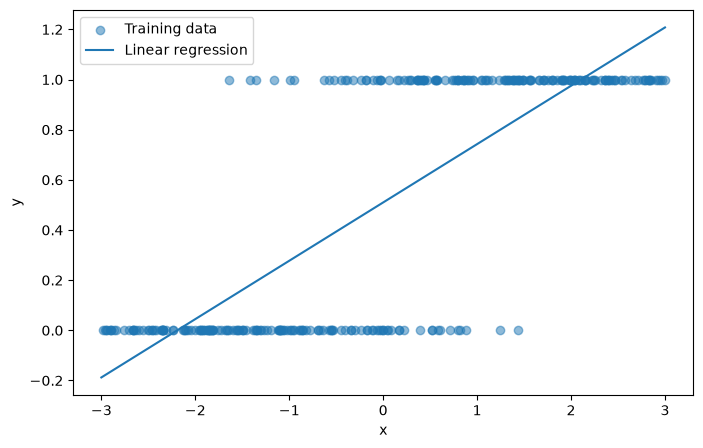

In [14]:
x = np.linspace(start=-3, stop=3, num=100)
y = model.predict(x.reshape(-1, 1))

plt.figure(figsize=(8, 5))

plt.scatter(X_train, y_train, label="Training data", alpha=0.5)

plt.plot(x, y, "-", label="Linear regression")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [15]:
logistic_model = LogisticRegression(C=np.inf)
logistic_model.fit(X_train, y_train)

logistic_y_train_proba = logistic_model.predict_proba(X_train)
logistic_y_test_proba = logistic_model.predict_proba(X_test)

print(logistic_y_train_proba[:5])
print(logistic_y_test_proba[:5])

[[0.00260872 0.99739128]
 [0.99540012 0.00459988]
 [0.9730911  0.0269089 ]
 [0.80931887 0.19068113]
 [0.07115763 0.92884237]]
[[0.97669406 0.02330594]
 [0.27790234 0.72209766]
 [0.36580678 0.63419322]
 [0.98690345 0.01309655]
 [0.48323015 0.51676985]]


In [16]:
train_logloss = log_loss(y_train, logistic_y_train_proba)
test_logloss = log_loss(y_test, logistic_y_test_proba)

print("Train Log Loss:", train_logloss)
print("Test Log Loss:", test_logloss)

Train Log Loss: 0.28372072605987264
Test Log Loss: 0.31449393505054457


/Users/riku.personal/miniconda3/envs/ml1/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


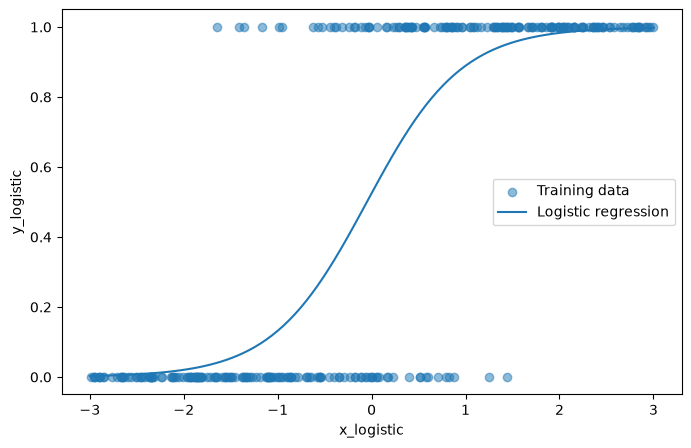

In [17]:
x_logistic = np.linspace(start=-3, stop=3, num=100)
y_logistic = logistic_model.predict_proba(x_logistic.reshape(-1, 1))[:, 1]

plt.figure(figsize=(8, 5))

plt.scatter(X_train, y_train, label="Training data", alpha=0.5)

plt.plot(x_logistic, y_logistic, "-", label="Logistic regression")

plt.xlabel("x_logistic")
plt.ylabel("y_logistic")
plt.legend()
plt.show()

In [18]:
# Ex 3b
t = 0.5 # baseline threshold for classification 0.83

logistic_predictions = (logistic_y_test_proba[:, 1] >= t).astype(int)
logistic_predictions_test_accuracy = accuracy_score(y_test, logistic_predictions)

print("Test Accuracy:", logistic_predictions_test_accuracy)

Test Accuracy: 0.83


In [19]:
correct = (y_test == logistic_predictions).sum()
total = len(y_test)

manual_accuracy = correct / total

print(correct, total, manual_accuracy)

83 100 0.83


In [20]:
thresholds = np.linspace(0, 1, 1001)
accuracies = {}

for t in thresholds:
    logistic_predictions = (logistic_y_test_proba[:, 1] >= t).astype(int)
    logistic_predictions_test_accuracy = accuracy_score(y_test, logistic_predictions)
    accuracies[float(t)] = logistic_predictions_test_accuracy

print("Top 5 Test Accuracy:", sorted(accuracies.items(), key=lambda x: x[1], reverse=True)[:5])

Top 5 Test Accuracy: [(0.321, 0.87), (0.322, 0.86), (0.323, 0.86), (0.324, 0.86), (0.325, 0.86)]


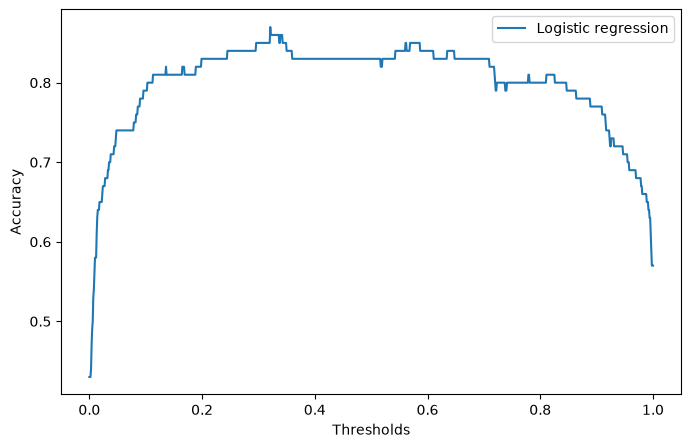

In [21]:
threshold_values = np.array(list(accuracies.keys()))
accuracy_values = np.array(list(accuracies.values()))

plt.figure(figsize=(8, 5))

plt.plot(threshold_values, accuracy_values, "-", label="Logistic regression")

plt.xlabel("Thresholds")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Top 5 Test Accuracy: [(0.41100000000000003, 0.86), (0.41200000000000003, 0.86), (0.41300000000000003, 0.86), (0.41400000000000003, 0.86), (0.41500000000000004, 0.86)]


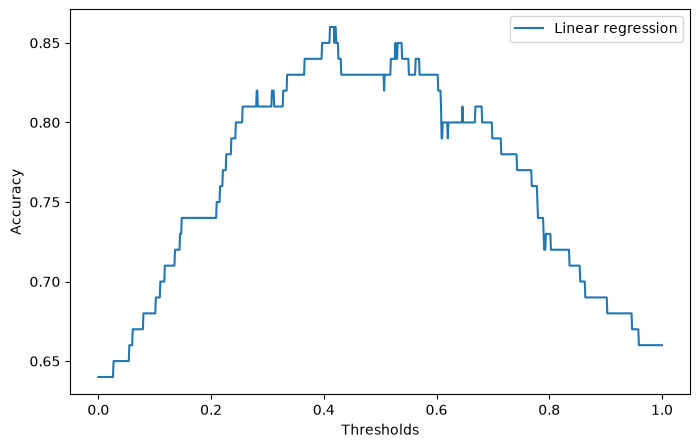

In [22]:
linreg_accuracies = {}

for t in thresholds:
    linreg_predictions = (y_test_pred >= t).astype(int)
    linreg_predictions_test_accuracy = accuracy_score(y_test, linreg_predictions)
    linreg_accuracies[float(t)] = linreg_predictions_test_accuracy

print("Top 5 Test Accuracy:", sorted(linreg_accuracies.items(), key=lambda x: x[1], reverse=True)[:5])

threshold_linreg_values = np.array(list(linreg_accuracies.keys()))
accuracy_linreg_values = np.array(list(linreg_accuracies.values()))

plt.figure(figsize=(8, 5))

plt.plot(threshold_linreg_values, accuracy_linreg_values, "-", label="Linear regression")

plt.xlabel("Thresholds")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

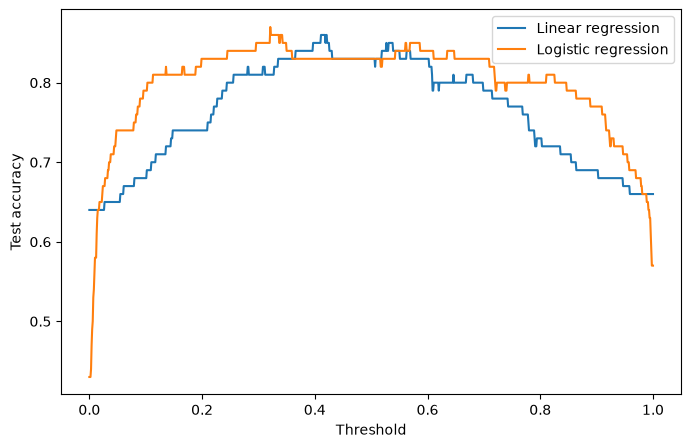

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(threshold_linreg_values, accuracy_linreg_values, label="Linear regression")
plt.plot(threshold_values, accuracy_values, label="Logistic regression")

plt.xlabel("Threshold")
plt.ylabel("Test accuracy")
plt.legend()
plt.show()

In [24]:
probs = logistic_y_test_proba[:, 1]

extreme_mask = (probs < 0.1) | (probs > 0.9)
print("Number of extreme predictions:", extreme_mask.sum())

Number of extreme predictions: 58


In [25]:
t = 0.5 # baseline threshold for classification 0.83

extreme_y_test = y_test[extreme_mask]

logistic_predictions = (logistic_y_test_proba[extreme_mask, 1] >= t).astype(int)
logistic_predictions_test_accuracy = accuracy_score(extreme_y_test, logistic_predictions)

print("Test Accuracy:", logistic_predictions_test_accuracy)

Test Accuracy: 0.9827586206896551


In [26]:
linreg_extreme_mask = (y_test_pred < 0.1) | (y_test_pred > 0.9)
print("Number of extreme predictions:", linreg_extreme_mask.sum())

Number of extreme predictions: 37


In [27]:
t = 0.5 # baseline threshold for classification 0.83

extreme_linreg_y_test = y_test[linreg_extreme_mask]

linreg_predictions = (y_test_pred[linreg_extreme_mask] >= t).astype(int)

linreg_predictions_test_accuracy = accuracy_score(extreme_linreg_y_test, linreg_predictions)

print("Linreg Test Accuracy:", linreg_predictions_test_accuracy)

Linreg Test Accuracy: 1.0


In [28]:
# Ex 4
def f(x):
    x1,x2 = x
    fx = (x1**2+x2-11)**2 + (x1+x2**2-7)**2
    return fx

def g(x):
    x1,x2 = x
    gx = np.array([4*x1*(x1**2+x2-11) + 2*(x1+x2**2-7), 2*(x1**2+x2-11) + 4*x2*(x1+x2**2-7)])
    return gx

def gradient_descent(f, g, x0, e, iter_amount):
    x = np.array(x0, dtype=float)
    x_history = []
    f_history = []

    x_history.append(x.copy())
    f_history.append(f(x))

    for _ in range(iter_amount):
        x -= e * g(x)
        x_history.append(x.copy())
        f_history.append(f(x))
    return x, x_history, f_history

In [29]:
# Ex 4b
x, x_history, f_history = gradient_descent(f, g, x0=[0, -1], e=0.003, iter_amount=1000)
path = np.array(x_history)
print("Final point:", x)
print("Final function value:", f(x))
print("History of points:", x_history)
print("History of function values:", f_history)

Final point: [ 3.58442834 -1.84812653]
Final function value: 3.155443620884047e-29
History of points: [array([ 0., -1.]), array([ 0.036, -1.   ]), array([ 0.07696744, -0.99957578]), array([ 0.12358817, -0.99867028]), array([ 0.17663466, -0.99722492]), array([ 0.23697149, -0.99518156]), array([ 0.30555785, -0.99248533]), array([ 0.38344477, -0.98908874]), array([ 0.47176363, -0.98495724]), array([ 0.57170105, -0.9800767 ]), array([ 0.68445354, -0.97446305]), array([ 0.81115311, -0.96817439]), array([ 0.95275371, -0.9613254 ]), array([ 1.10986845, -0.95410347]), array([ 1.28255141, -0.94678484]), array([ 1.47002947, -0.93974769]), array([ 1.67041134, -0.93347747]), array([ 1.88043552, -0.92855789]), array([ 2.0953587 , -0.92564106]), array([ 2.30911085, -0.92539244]), array([ 2.51481677, -0.92841347]), array([ 2.70567588, -0.93515509]), array([ 2.87601796, -0.94584488]), array([ 3.02220461, -0.96045236]), array([ 3.14305211, -0.97870592]), array([ 3.23964885, -1.00015454]), array([ 3.314

In [30]:
x1, x1_history, f1_history = gradient_descent(f, g, x0=[0, 4], e=0.001, iter_amount=1000)
path1 = np.array(x1_history)
print("Final point:", x1)
print("Final function value:", f(x1))
print("History of points:", x1_history)
print("History of function values:", f1_history)

Final point: [-2.80511809  3.13131252]
Final function value: 6.563322731438818e-28
History of points: [array([0., 4.]), array([-0.018,  3.87 ]), array([-0.03443114,  3.76105558]), array([-0.04965017,  3.66855001]), array([-0.06392293,  3.58916677]), array([-0.07745316,  3.52045037]), array([-0.0904008 ,  3.46053696]), array([-0.10289397,  3.40798182]), array([-0.11503719,  3.36164498]), array([-0.12691712,  3.32061295]), array([-0.13860664,  3.28414388]), array([-0.15016785,  3.25162815]), array([-0.16165436,  3.22255957]), array([-0.17311297,  3.19651391]), array([-0.18458493,  3.17313267]), array([-0.19610703,  3.15211064]), array([-0.20771236,  3.13318623]), array([-0.21943094,  3.11613383]), array([-0.23129025,  3.10075786]), array([-0.24331565,  3.08688786]), array([-0.25553069,  3.0743746 ]), array([-0.26795741,  3.06308689]), array([-0.28061655,  3.05290899]), array([-0.29352778,  3.04373838]), array([-0.30670979,  3.035484  ]), array([-0.32018046,  3.02806471]), array([-0.33395

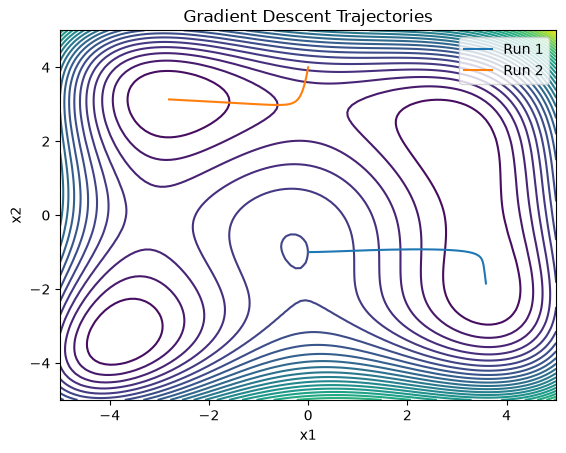

In [31]:
x,y=np.linspace(-5,5,100),np.linspace(-5,5,100)
xgrid,ygrid=np.meshgrid(x,y)
zgrid=f(np.array([xgrid, ygrid]))
plt.contour(xgrid,ygrid,zgrid,levels=30)
plt.plot(path[:, 0], path[:, 1], label="Run 1")
plt.plot(path1[:, 0], path1[:, 1], label="Run 2")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Gradient Descent Trajectories")
plt.legend()
plt.show()

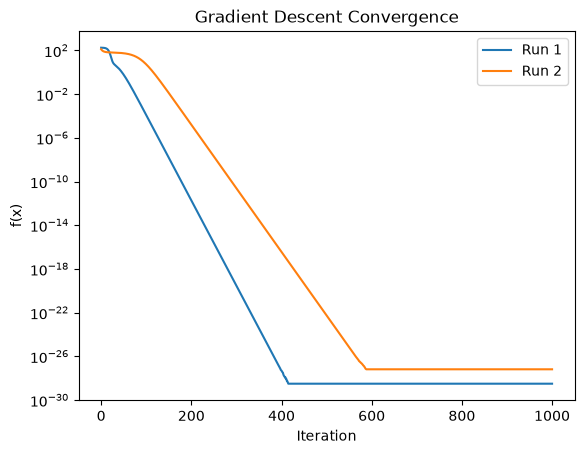

In [32]:
plt.plot(f_history, label="Run 1")
plt.plot(f1_history, label="Run 2")
plt.legend()
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("f(x)")
plt.title("Gradient Descent Convergence")
plt.show()

In [33]:
# Ex 4c
x0 = np.array([-1, -2], dtype=float)
e = 0.01

x_new = x0 - e * g(x0)

print("Initial function value:", f(x0))
print("New function value:", f(x_new))

Initial function value: 160.0
New function value: 140.24861696000002


In [34]:
# Ex 4c
x0 = np.array([-1, -2], dtype=float)
e = 0.001

x_new = x0 - e * g(x0)

print("Initial function value:", f(x0))
print("New function value:", f(x_new))

Initial function value: 160.0
New function value: 158.302567940096


In [36]:
# Ex 4c
x0 = np.array([-1, -2], dtype=float)
e = 0.05

x_new = x0 - e * g(x0)

print("Initial function value:", f(x0))
print("New function value:", f(x_new))

Initial function value: 160.0
New function value: 37.33760000000001


In [38]:
# Ex 4c
x0 = np.array([-1, -2], dtype=float)
e = 0.2

x_new = x0 - e * g(x0)

print("Initial function value:", f(x0))
print("New function value:", f(x_new))

Initial function value: 160.0
New function value: 4418.201600000001


In [43]:
x0 = np.array([-1, -2], dtype=float)
step_sizes = np.linspace(0.001, 0.2, 200)

largest_step = None

for e in step_sizes:
    x_new = x0 - e * g(x0)

    if f(x_new) < f(x0):
        largest_step = e

print("Largest valid step:", largest_step)
largest_not_increasing = largest_step

Largest valid step: 0.101


In [45]:
x0 = np.array([-1, -2], dtype=float)
step_sizes = np.linspace(0.101, 0.102, 1001)

largest_step = None

for e in step_sizes:
    x_new = x0 - e * g(x0)

    if f(x_new) < f(x0):
        largest_step = e

print("Largest valid step:", largest_step)
largest_not_increasing = largest_step

Largest valid step: 0.101895


In [47]:
x0 = np.array([-1, -2], dtype=float)
step_sizes = np.linspace(0, largest_not_increasing, 1001)

best_step = None
smallest_function_value = f(x0)

for e in step_sizes:
    x_new = x0 - e * g(x0)

    if f(x_new) < smallest_function_value:
        best_step = e
        smallest_function_value = f(x_new) 

print("Best step:", best_step, smallest_function_value)

Best step: 0.06704691 18.051648450159686


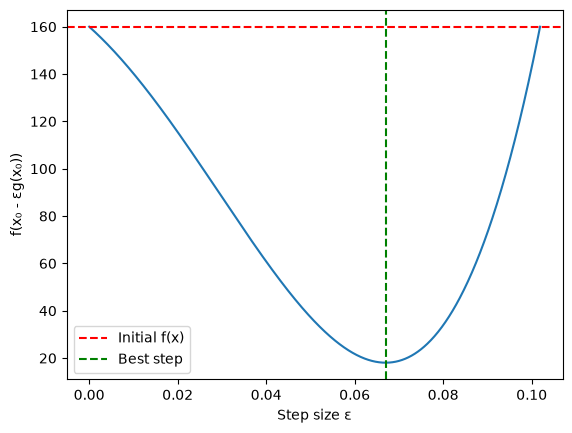

In [49]:
plt.plot(step_sizes, [f(x0 - e * g(x0)) for e in step_sizes])

plt.axhline(f(x0), color="red", linestyle="--", label="Initial f(x)")
plt.axvline(best_step, color="green", linestyle="--", label="Best step")

plt.xlabel("Step size ε")
plt.ylabel("f(x₀ - εg(x₀))")
plt.legend()
plt.show()